# Multimodal Transformers: Describe or Embed

Multimodal transformers offer two paths across the semantic gap. The first path generates text
that describes an image and then searches the text with the toolkit of the earlier chapters. The
second path maps images and text into one shared embedding space and compares them directly.
This notebook follows the book section *Multimodal Transformers*: it runs the two-step metadata
pipeline of Figure 9.13 with Claude, evaluates the generated metadata and provokes a
hallucination, reproduces the CLIP zero-shot example of the book, and finally sends the same
queries down both paths.

**Learning goals:**
- Generate a description and structured JSON metadata for a photo with a multimodal language model
- Turn the JSON fields into text fields, keyword fields, and filters of an index
- Evaluate generated metadata against ground truth, and see how a prompt can force a hallucination
- Compute CLIP similarities between images and captions, and classify images zero-shot
- Compare the describe path and the embedding path on the same queries, and fuse them

**Prerequisites:** Chapter 1 (BM25), Chapter 5 (hybrid search and reciprocal rank fusion), demos ch09-01 and ch09-02

**Data:** the photo collection of demo ch09-02 plus the Taj Mahal photo of demo ch09-01
(`data/ch09/SOURCES.md`, `data/images/SOURCES.md`). CLIP is `openai/clip-vit-base-patch32`
(about 600 MB on the first run).

<div style="border-left: 4px solid #64748B; background: rgba(100, 116, 139, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#64748B; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">Claude on AWS Bedrock, and recorded answers</strong><br>
The describe path calls Claude on AWS Bedrock. With <code>LIVE = False</code>, the notebook replays the answers recorded in <code>data/ch09/llm_metadata.json</code>, so it runs offline and shows the outputs the text discusses. With <code>LIVE = True</code>, or after you change a prompt, it asks Claude again; a new run gives similar but not identical answers.
</div>

## Setup

In [1]:
import json
import os
import re
from collections import defaultdict
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"   # quiet model downloads
os.environ["HF_HUB_VERBOSITY"] = "error"
import torch
from transformers import CLIPModel, CLIPProcessor
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()

from shared.display import print_table, display_md
from shared.llm import AWSConnectionError, invoke_claude
from shared.retrieval import document_frequencies, idf_lucene, rank_collection_bm25
from shared.text import pipeline
from ch09_media import DATA, IMAGES, distance_km, gps_position, load_images

LIVE = False                     # True: ask Claude on Bedrock instead of replaying the recording
RECORDED = json.loads((DATA / "ch09" / "llm_metadata.json").read_text(encoding="utf-8"))

images = load_images()
PATHS = {name: DATA / spec[0] for name, spec in IMAGES.items()}
PATHS["taj_mahal"] = DATA / "images" / "taj_mahal.jpg"          # the photo with GPS, from ch09-01

The helper `ask` sends a prompt and a photo to Claude. It replays the recorded answer unless
`LIVE` is set or the prompt differs from the recorded one.

In [2]:
def ask(field, prompt, name, max_tokens=1200):
    """Claude's answer to `prompt` about photo `name`; replays the recording when possible."""
    recorded = RECORDED["responses"].get(name, {}).get(field)
    if recorded is not None and not LIVE and RECORDED["prompts"].get(field) == prompt:
        return recorded
    try:
        return invoke_claude(prompt, image=PATHS[name].read_bytes(), max_tokens=max_tokens)
    except AWSConnectionError:
        if recorded is None:
            raise
        return recorded

def parse_json(text):
    """The first JSON object in a model answer (answers often wrap it in a code fence)."""
    return json.loads(re.search(r"\{.*\}", text, re.S).group(0))

display_md(f"Recorded answers: **{RECORDED['model']}**, {RECORDED['recorded']}. Mode: **{'live' if LIVE else 'replay'}**.")

Recorded answers: **us.anthropic.claude-sonnet-5-5**, 2026-11-02. Mode: **replay**.

## 1. Describe, Then Search Text

Figure 9.13 of the book runs two prompts on a photo of the Matterhorn. The first asks for a
detailed description, the second for a JSON document with predefined fields. These are the two
prompts of the figure.

In [3]:
DESCRIBE = """Please provide a detailed description of the image you see. Include information about:

- The main subject or focus of the image
- The setting or background
- Colors and lighting
- Any people, animals, or objects present
- The overall mood or atmosphere
- Any notable details or unique features
- The composition or layout of the image
- Any text or symbols visible
- The style or type of image (e.g., photograph, painting, digital art)
- Your personal impression or interpretation of the image

Be as specific and descriptive as possible, and try to paint a vivid picture with your words so that someone who hasn't seen the image can imagine it clearly."""

EXTRACT = """Analyze the given image and provide a JSON output with the following information:

{
  "headline": "A brief, catchy title summarizing the main subject or theme of the image",
  "keywords": ["List", "of", "relevant", "keywords", "describing", "the", "image", "content"],
  "named_entities": ["List", "of", "identified", "people", "places", "organizations", "or", "products"],
  "dominant_colors": ["List", "of", "primary", "colors", "present", "in", "the", "image"],
  "dominant_forms_shapes": ["List", "of", "main", "geometric", "shapes", "or", "forms", "observed"],
  "extracted_text": "Any text visible in the image, if present",
  "people_present": true/false,
  "is_selfie": true/false,
  "is_outdoors": true/false,
  "is_text_image": true/false
}

Please ensure that:
1. The "headline" is concise and accurately represents the image's main subject.
2. "keywords" include relevant terms describing the image's content, style, and context.
3. "named_entities" list any recognizable people, places, brands, or organizations.
4. "dominant_colors" list the most prominent colors in the image.
5. "dominant_forms_shapes" describe the main geometric shapes or forms observed.
6. "extracted_text" contains any visible text in the image, if applicable.
7. "people_present" is set to true if any human figures are visible in the image.
8. "is_selfie" is set to true if the image appears to be a self-taken photograph.
9. "is_outdoors" is set to true if the image depicts an outdoor scene.
10. "is_text_image" is set to true if the image primarily consists of text (e.g., a screenshot of text).

Provide the JSON output based on your analysis of the image."""

Step 1 on the Matterhorn photo:

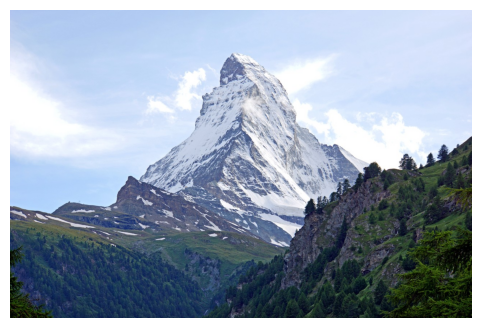

**Description (521 words):**

> **Main Subject**
> The image centers on a single, dramatic mountain peak with a sharp, pyramid-like summit. Its steep faces are streaked with snow and dark gray rock. The peak looks like the Matterhorn in the Swiss Alps, a shape recognized around the world. It rises well above the surrounding landscape and dominates the frame.
> 
> **Setting and Background**
> The photo was taken from a lower alpine valley or hillside. In the foreground and midground, green slopes are covered with dense evergreen forest, mostly spruce and larch. On the right, a rocky cliff face juts out of the hillside, with trees clinging to its ledges and grassy patches between the stones. On the left, a lower ridge carries scattered patches of leftover snow and a few small structures near its crest. Behind everything, the mountain stands against a pale sky.
> 
> **Colors and Lighting**
> The palette is cool and natural:
> - The sky is soft powder blue, with wispy white clouds drifting around the summit.
> - The mountain is mostly white snow broken up by slate-gray and charcoal rock ribs and gullies.
> - The lower slopes are deep forest green, with lighter yellow-green meadows in between.
> - The cliff on the right is warm brownish-gray.
> 
> The light is diffuse and even, probably from a partly cloudy or hazy day. It gives gentle contrast without harsh shadows, and it brings out the texture of the snow and rock.
> 
> **Living Things and Objects**
> There are no people or animals visible. The living elements are the conifers, which range from tiny dots on the far slopes to a large, detailed branch of dark green needles in the lower right corner. A small structure, possibly a lift station or hut, sits on the left ridge, but it is barely noticeable.
> 
> **Mood and Atmosphere**
> The mood is calm, majestic, and quietly awe-inspiring. The summer snow, fresh greenery, and open sky make the scene feel crisp and serene. A tiny wisp of cloud clings to the mountain's upper face and adds a sense of altitude and weather.
> 
> **Composition**
> The peak is placed slightly right of center, and its diagonal ridgelines lead the eye upward to the summit. Layers of landscape create depth: dark foreground trees, then the forested slopes and cliff, then the pale mountain, then the sky. The tree branch in the lower right and the cliff on the right frame the scene and balance the open sky on the left. The sloping hillsides on both sides form a loose V that funnels attention toward the mountain.
> 
> **Text or Symbols**
> None are visible.
> 
> **Style**
> This is a landscape photograph, sharp and naturally colored, probably taken with a zoom or telephoto lens to compress the distance and make the peak loom large.
> 
> **Personal Impression**
> The image shows how small the human world is next to the Alps. The jagged, snow-streaked summit feels timeless and a little austere, and the soft green forests below make it welcoming. It reads like a postcard, but its muted light and natural detail keep it from feeling staged. It makes me want to hike up into the valley and look up at the peak myself.

In [4]:
description = ask("describe", DESCRIBE, "matterhorn")
fig, ax = plt.subplots(figsize=(6, 4))
ax.imshow(images["matterhorn"])
ax.axis("off")
plt.show()
display_md(f"**Description ({len(description.split())} words):**\n\n" + "\n".join(f"> {line}" for line in description.splitlines()))

Step 2 on the same photo returns the structured document:

In [5]:
metadata = {name: parse_json(ask("extract", EXTRACT, name)) for name in PATHS}
display_md(f"```json\n{json.dumps(metadata['matterhorn'], indent=2, ensure_ascii=False)}\n```")

```json
{
  "headline": "Majestic Matterhorn Towering Over Alpine Forests",
  "keywords": [
    "Matterhorn",
    "mountain",
    "Alps",
    "snow-capped peak",
    "alpine landscape",
    "pyramid peak",
    "conifer forest",
    "pine trees",
    "rocky cliffs",
    "blue sky",
    "clouds",
    "Switzerland",
    "Zermatt",
    "nature",
    "scenic view",
    "hiking destination",
    "summer"
  ],
  "named_entities": [
    "Matterhorn",
    "Alps",
    "Zermatt",
    "Switzerland"
  ],
  "dominant_colors": [
    "white",
    "blue",
    "green",
    "gray",
    "dark green",
    "brown"
  ],
  "dominant_forms_shapes": [
    "triangular pyramid peak",
    "jagged ridges",
    "diagonal slopes",
    "conical conifer trees",
    "rounded clouds",
    "steep rocky cliffs"
  ],
  "extracted_text": "",
  "people_present": false,
  "is_selfie": false,
  "is_outdoors": true,
  "is_text_image": false
}
```

The model names a specific entity, the Matterhorn, and adds Zermatt and Switzerland. It also
fills every field of the schema: colors, shapes, and the boolean flags. We run the second prompt
on all ten photos.

In [6]:
rows = [[name, m["headline"], ", ".join(m["named_entities"]) or "(none)",
         "yes" if m["people_present"] else "no", "yes" if m["is_outdoors"] else "no"]
        for name, m in metadata.items()]
print_table(rows, headers=["Photo", "headline", "named_entities", "people_present", "is_outdoors"])

| Photo      | headline                                                            | named_entities                                                    | people_present   | is_outdoors   |
|:-----------|:--------------------------------------------------------------------|:------------------------------------------------------------------|:-----------------|:--------------|
| taj_a      | Taj Mahal Reflected in Tranquil Gardens at Agra                     | Taj Mahal, Agra, India, Mughal Empire                             | yes              | yes           |
| taj_b      | Timeless Majesty: Crowds Gather at the Taj Mahal                    | Taj Mahal, Agra, India                                            | yes              | yes           |
| matterhorn | Majestic Matterhorn Towering Over Alpine Forests                    | Matterhorn, Alps, Zermatt, Switzerland                            | no               | yes           |
| mt_forbes  | Alpenglow Ignites a Snow-Covered Peak at Twilight                   | (none)                                                            | no               | yes           |
| black_cat  | Sleek Black Cat Lounging on a Quilted Blue Bedspread                | (none)                                                            | no               | no            |
| ginger_cat | Curious Ginger Kitten Lounging in Lush Green Grass                  | (none)                                                            | no               | yes           |
| red_car    | Matte Red Ferrari 599 GTB Fiorano Glows on a Night-Time City Street | Ferrari, Ferrari 599 GTB Fiorano, Prancing Horse logo, Tod's      | yes              | yes           |
| sunset     | Fiery Sun Sinking Behind a Forested Ridge                           | (none)                                                            | no               | yes           |
| federer    | Eyes on the Ball: Tennis Player Mid-Serve on Grass                  | Wilson (racket brand), Nike (apparel brand, swoosh logo on shirt) | yes              | yes           |
| taj_mahal  | Taj Mahal Majesty: Reflections and Gardens in Agra                  | Taj Mahal, Agra, India                                            | yes              | yes           |

### The fields become an index

Each field has a place in the index of Chapter 4. The headline, the description, and the
keywords become a text field for BM25. The named entities become a keyword field for exact
matches and facets. The boolean flags become filters. We build both for the nine photos of the
collection. The descriptions of step 1 serve as the long text.

In [7]:
names = list(IMAGES)
descriptions = {name: ask("describe", DESCRIBE, name) for name in names}
text_field = {name: pipeline(" ".join([metadata[name]["headline"], descriptions[name],
                                       " ".join(metadata[name]["keywords"]),
                                       " ".join(metadata[name]["named_entities"])]))
              for name in names}
df = document_frequencies(text_field)

def search_text(query, k=3):
    """BM25 over the generated text; Lucene IDF stays positive in a collection of nine photos."""
    ranked = rank_collection_bm25(pipeline(query), text_field, df, idf_fn=idf_lucene)
    return [(name, score) for name, score in ranked if score > 0][:k]

def entity_match(entity):
    """Photos whose named_entities contain the entity (case-insensitive)."""
    return [n for n in names if any(entity.lower() in e.lower() for e in metadata[n]["named_entities"])]

def outdoor_without_people():
    """A filter query on the boolean fields."""
    return [n for n in names if metadata[n]["is_outdoors"] and not metadata[n]["people_present"]]

display_md(
    f"| Query | Kind | Result |\n|---|---|---|\n"
    f"| white marble mausoleum | BM25 on text | {', '.join(f'{n} ({s:.1f})' for n, s in search_text('white marble mausoleum'))} |\n"
    f"| Ferrari | named entity | {', '.join(entity_match('Ferrari'))} |\n"
    f"| outdoor photos without people | filter | {', '.join(outdoor_without_people())} |"
)

| Query | Kind | Result |
|---|---|---|
| white marble mausoleum | BM25 on text | taj_a (4.6), taj_b (4.6), federer (0.1) |
| Ferrari | named entity | red_car |
| outdoor photos without people | filter | matterhorn, mt_forbes, ginger_cat, sunset |

The filter returns exactly the outdoor photos without people. "Without people" is a field value
here, not a word that has to appear in a text. The price is that the index contains only what the model
chose to write, and a large model must process every photo, again whenever the prompt changes.

## 2. The Eighth Obstacle: Hallucination

Generated metadata reads well, so it is tempting to trust it after a few examples. The book
recommends evaluating it like any other classifier: compare the generated fields with ground truth.
For our ten photos, we know who and what is in each one.

In [8]:
TRUTH = {   # photo: (people present, outdoors, main named entity or None)
    "taj_a": (True, True, "Taj Mahal"),     "taj_b": (True, True, "Taj Mahal"),
    "taj_mahal": (True, True, "Taj Mahal"), "matterhorn": (False, True, "Matterhorn"),
    "mt_forbes": (False, True, "Mount Forbes"),
    "black_cat": (False, False, None),      "ginger_cat": (False, True, None),
    "red_car": (None, True, "Ferrari"),     # a blurred figure at a shop window: person or mannequin?
    "sunset": (False, True, None),          "federer": (True, True, "Roger Federer"),
}

def entity_verdict(expected, generated):
    """correct, missing, or (for photos without a known entity) correctly empty or extra."""
    if expected is None:
        return "correctly empty" if not generated else "extra: " + ", ".join(generated)
    if any(expected.lower() in g.lower() for g in generated):
        return "correct"
    return "missing" if not generated else "missing; names " + ", ".join(generated)

rows, counts = [], defaultdict(int)
for name, (people, outdoors, entity) in TRUTH.items():
    m = metadata[name]
    verdict = entity_verdict(entity, m["named_entities"])
    counts["people"] += people is not None and m["people_present"] == people
    counts["people_n"] += people is not None
    counts["outdoors"] += m["is_outdoors"] == outdoors
    counts[verdict.split(";")[0].split(":")[0]] += 1
    rows.append([name, entity or "(none)", verdict,
                 "n/a" if people is None else ("ok" if m["people_present"] == people else "wrong"),
                 "ok" if m["is_outdoors"] == outdoors else "wrong"])
print_table(rows, headers=["Photo", "Expected entity", "named_entities", "people_present", "is_outdoors"])
display_md(
    f"**people_present:** {counts['people']} of {counts['people_n']} correct · "
    f"**is_outdoors:** {counts['outdoors']} of {len(TRUTH)} correct · "
    f"**main entity:** {counts['correct']} correct, {counts['missing']} missing, "
    f"{counts['correctly empty']} correctly empty, {counts['extra']} extra"
)

| Photo      | Expected entity   | named_entities                                                                   | people_present   | is_outdoors   |
|:-----------|:------------------|:---------------------------------------------------------------------------------|:-----------------|:--------------|
| taj_a      | Taj Mahal         | correct                                                                          | ok               | ok            |
| taj_b      | Taj Mahal         | correct                                                                          | ok               | ok            |
| taj_mahal  | Taj Mahal         | correct                                                                          | ok               | ok            |
| matterhorn | Matterhorn        | correct                                                                          | ok               | ok            |
| mt_forbes  | Mount Forbes      | missing                                                                          | ok               | ok            |
| black_cat  | (none)            | correctly empty                                                                  | ok               | ok            |
| ginger_cat | (none)            | correctly empty                                                                  | ok               | ok            |
| red_car    | Ferrari           | correct                                                                          | n/a              | ok            |
| sunset     | (none)            | correctly empty                                                                  | ok               | ok            |
| federer    | Roger Federer     | missing; names Wilson (racket brand), Nike (apparel brand, swoosh logo on shirt) | ok               | ok            |

**people_present:** 9 of 9 correct · **is_outdoors:** 10 of 10 correct · **main entity:** 5 correct, 2 missing, 3 correctly empty, 0 extra

In this run, the fields are accurate, and the errors are omissions, not inventions. The model
leaves Mt. Forbes unnamed rather than guessing. It names the racket and shirt brands in the
tennis photo but not the player: Claude does not identify people from their faces. A news archive
would add a face recognition step, one of the specialized solutions in the next book section. The
red car shows a second difficulty: a blurred figure at a shop window makes even the ground truth
unclear.

### Forcing an answer

The book warns that a language model fills gaps with plausible guesses when the evidence is weak.
Whether it does depends on the prompt. We ask for the name of the mountain twice, once with no way
out and once with permission to say "unknown", three times each.

In [9]:
NAME_FORCED = "Which mountain is shown in this photo? Reply with its name only, no explanation."
NAME_HEDGED = ("Which mountain is shown in this photo? Reply with its name only. If you cannot identify it "
               "with confidence from the image, reply exactly: unknown.")

def ask_three_times(field, prompt, name):
    """Three answers to the same prompt: the three recorded runs, or three live calls."""
    first = ask(field, prompt, name, max_tokens=600)
    return first if isinstance(first, list) else [first] + [ask(field, prompt, name, max_tokens=600) for _ in range(2)]

rows = []
for name, truth in [("matterhorn", "Matterhorn"), ("mt_forbes", "Mount Forbes")]:
    for label, field, prompt in [("forced", "name_forced", NAME_FORCED), ("hedged", "name_hedged", NAME_HEDGED)]:
        rows.append([name, truth, label, " · ".join(a.strip() for a in ask_three_times(field, prompt, name))])
print_table(rows, headers=["Photo", "Actual mountain", "Prompt", "Three answers"])

| Photo      | Actual mountain   | Prompt   | Three answers                               |
|:-----------|:------------------|:---------|:--------------------------------------------|
| matterhorn | Matterhorn        | forced   | Matterhorn · Matterhorn · Matterhorn        |
| matterhorn | Matterhorn        | hedged   | Matterhorn · Matterhorn · Matterhorn        |
| mt_forbes  | Mount Forbes      | forced   | Mount Alberta · Mount Alberta · Mount Bryce |
| mt_forbes  | Mount Forbes      | hedged   | unknown · unknown · unknown                 |

For the Matterhorn, both prompts give the right name every time. For Mt. Forbes, the forced
prompt produces confident names of other peaks in the Canadian Rockies, and they change from run
to run. The hedged prompt says "unknown". The same model is cautious or inventive depending on
what the prompt allows, which is why the book recommends prompts that permit empty fields.
Disagreement between repeated runs is a cheap warning sign as well.

### Cross-checking with independent metadata

Generated values can be checked against metadata that the model did not write. The Taj Mahal
photo of demo ch09-01 carries its GPS position in EXIF. If the model claims the Taj Mahal, the
position must be close to it.

In [10]:
TAJ_MAHAL = (27 + 10 / 60 + 30 / 3600, 78 + 2 / 60 + 31 / 3600)     # the mausoleum
claimed = metadata["taj_mahal"]["named_entities"]
position = gps_position(PATHS["taj_mahal"])
d = distance_km(position, TAJ_MAHAL)
display_md(
    f"**Generated entities:** {', '.join(claimed)}  \n"
    f"**EXIF GPS:** {position[0]:.4f} N, {position[1]:.4f} E, {d:.2f} km from the mausoleum: "
    f"**{'consistent' if d < 2 else 'inconsistent'}** with the claim."
)

**Generated entities:** Taj Mahal, Agra, India  
**EXIF GPS:** 27.1719 N, 78.0421 E, 0.34 km from the mausoleum: **consistent** with the claim.

Most photos have no GPS tags: our Mt. Forbes photo has none, and an upload often removes them,
as demo ch09-01 showed. Other independent sources are the photographer's caption, the web page
around the image, or a controlled list of the entities that an archive expects.

## 3. A Shared Embedding Space: CLIP

CLIP trains an image encoder and a text encoder so that an image and its caption end up close
together. In each training step, it compares every image of a batch with every caption: the
diagonal of the similarity matrix holds the matching pairs. We build such a matrix for our nine
photos, with one short caption each.

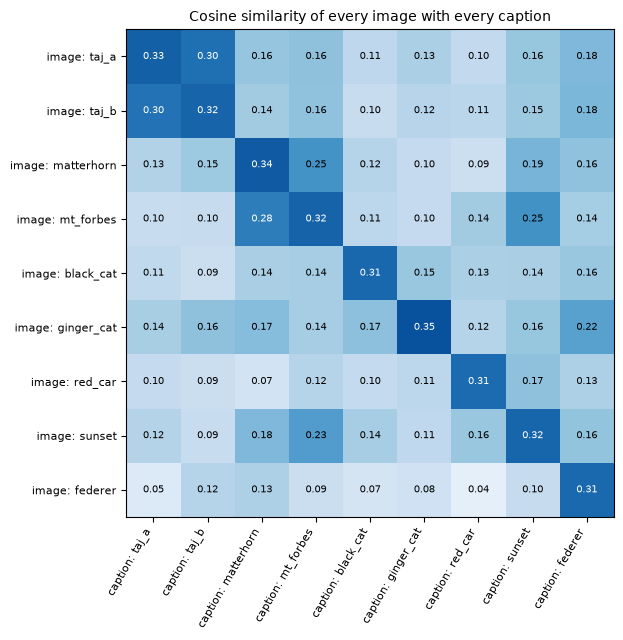

| Image      |   Cosine with own caption | Second-best caption   |   Softmax on own caption |
|:-----------|--------------------------:|:----------------------|-------------------------:|
| taj_a      |                     0.325 | taj_b                 |                    90.3% |
| taj_b      |                     0.319 | taj_a                 |                    89.2% |
| matterhorn |                     0.335 | mt_forbes             |                   100.0% |
| mt_forbes  |                     0.321 | matterhorn            |                    98.2% |
| black_cat  |                     0.314 | federer               |                   100.0% |
| ginger_cat |                     0.350 | federer               |                   100.0% |
| red_car    |                     0.309 | sunset                |                   100.0% |
| sunset     |                     0.318 | mt_forbes             |                   100.0% |
| federer    |                     0.312 | matterhorn            |                   100.0% |

In [11]:
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").eval()
TAU = 1 / clip.logit_scale.exp().item()                  # learned temperature: 0.01

def embed_images(imgs):
    """Unit-length CLIP image embeddings."""
    with torch.no_grad():
        v = clip.get_image_features(**processor(images=list(imgs), return_tensors="pt")).pooler_output
    return (v / v.norm(dim=-1, keepdim=True)).numpy()

def embed_texts(texts):
    """Unit-length CLIP text embeddings."""
    with torch.no_grad():
        t = clip.get_text_features(**processor(text=list(texts), return_tensors="pt", padding=True)).pooler_output
    return (t / t.norm(dim=-1, keepdim=True)).numpy()

CAPTIONS = {
    "taj_a": "a photo of the Taj Mahal behind a long reflecting pool",
    "taj_b": "a photo of the Taj Mahal with crowds in the garden",
    "matterhorn": "a photo of the Matterhorn above a green forest",
    "mt_forbes": "a photo of a pink mountain peak at dusk",
    "black_cat": "a photo of a black cat lying on a quilt",
    "ginger_cat": "a photo of a ginger kitten in the grass",
    "red_car": "a photo of a red sports car on a street at night",
    "sunset": "a photo of a red sunset over a forested ridge",
    "federer": "a photo of a tennis player serving on grass",
}
V = embed_images(images[n] for n in names)
S = V @ embed_texts(CAPTIONS[n] for n in names).T
P = np.exp((S - S.max(axis=1, keepdims=True)) / TAU)
P /= P.sum(axis=1, keepdims=True)                        # softmax over each row, as in the loss

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.imshow(S, cmap="Blues", vmin=0, vmax=0.4)
ax.set_xticks(range(len(names)), [f"caption: {n}" for n in names], rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(names)), [f"image: {n}" for n in names], fontsize=8)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f"{S[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if S[i, j] > 0.28 else "black")
ax.set_title("Cosine similarity of every image with every caption", fontsize=10)
plt.tight_layout()
plt.show()

print_table([[n, S[i, i], names[int(np.argsort(-S[i])[1])], P[i, i]] for i, n in enumerate(names)],
            headers=["Image", "Cosine with own caption", "Second-best caption", "Softmax on own caption"],
            floatfmt=("", ".3f", "", ".1%"))

Every image is closest to its own caption, as the contrastive loss demands. The values are low,
around 0.3, and the softmax with temperature τ = 0.01 turns small differences into clear
decisions. The two Taj Mahal photos show the case of the book's note "What if two captions fit
the same image?": each Taj photo gives the other Taj caption a share of about a tenth, because
both captions fit.

### Zero-shot classification: the book's example

The book classifies the Matterhorn photo with five prompts. We repeat the computation step by
step: cosine, score $s_c = \cos / \tau$, the exponential after subtracting $s_{\max}$, and the
softmax.

In [12]:
PROMPTS = ["a photo of a mountain", "a photo of a building", "a photo of a tennis player",
           "a photo of a city", "a photo of a dog"]
T_prompts = embed_texts(PROMPTS)

def zero_shot(name, prompts=PROMPTS, T=T_prompts):
    """Cosines, scores, shifted exponentials, and probabilities of one photo against the prompts."""
    cos = embed_images([images[name]])[0] @ T.T
    s = cos / TAU
    e = np.exp(s - s.max())
    return cos, s, e, e / e.sum()

cos, s, e, p = zero_shot("matterhorn")
order = np.argsort(-cos)
print_table([[PROMPTS[i], cos[i], s[i], e[i], p[i]] for i in order],
            headers=["Prompt", "cos", "s = cos / τ", "exp(s − s_max)", "p"],
            floatfmt=("", ".3f", ".1f", ".5f", ".2%"))

cos_f, _, _, p_f = zero_shot("federer")
others = np.delete(cos_f, 2)
display_md(
    f"Sum of the exponentials: **{e.sum():.4f}**, so p(mountain) = 1 / {e.sum():.4f} = **{p[0]:.2%}**.  \n"
    f"Federer: p(tennis player) = **{p_f[2]:.4%}**, cosine {cos_f[2]:.3f} against {others.min():.3f} to {others.max():.3f}."
)

| Prompt                     |   cos |   s = cos / τ |   exp(s − s_max) |      p |
|:---------------------------|------:|--------------:|-----------------:|-------:|
| a photo of a mountain      | 0.293 |          29.3 |          1.00000 | 99.85% |
| a photo of a building      | 0.221 |          22.1 |          0.00074 |  0.07% |
| a photo of a tennis player | 0.213 |          21.3 |          0.00033 |  0.03% |
| a photo of a city          | 0.212 |          21.2 |          0.00031 |  0.03% |
| a photo of a dog           | 0.202 |          20.2 |          0.00012 |  0.01% |

Sum of the exponentials: **1.0015**, so p(mountain) = 1 / 1.0015 = **99.85%**.  
Federer: p(tennis player) = **99.9998%**, cosine 0.304 against 0.157 to 0.163.

The values match the worked example in the book: 0.293 against 0.221 and lower, and 99.85% for
"a photo of a mountain". The exponentials differ in the last digit because the book rounds the
cosines to three decimals before it computes them. The best cosine is only 0.293, so a threshold such as "relevant if
above 0.5" would reject every image. The information lies in the differences between the
candidates.

### Zero-shot with our own classes

Zero-shot classification works for any list of classes, without training. In demo ch09-02,
ResNet-50 called the Taj Mahal a "mosque" and the sunset a "balloon", because ImageNet has no
such classes. With CLIP, we simply write the classes we need.

In [13]:
CLASSES = ["a photo of a mausoleum", "a photo of a mountain", "a photo of a cat",
           "a photo of a car", "a photo of a sunset", "a photo of a tennis player"]
T_classes = embed_texts(CLASSES)
rows = []
for name in names:
    _, _, _, p = zero_shot(name, CLASSES, T_classes)
    rows.append([name, IMAGES[name][2], CLASSES[int(p.argmax())].removeprefix("a photo of a "), p.max()])
print_table(rows, headers=["Photo", "Actual content", "CLIP class", "p"], floatfmt=("", "", "", ".1%"))

| Photo      | Actual content   | CLIP class    |      p |
|:-----------|:-----------------|:--------------|-------:|
| taj_a      | Taj Mahal        | mausoleum     |  99.1% |
| taj_b      | Taj Mahal        | mausoleum     |  99.5% |
| matterhorn | mountain         | mountain      |  99.9% |
| mt_forbes  | mountain         | mountain      |  98.9% |
| black_cat  | cat              | cat           |  99.8% |
| ginger_cat | cat              | cat           |  99.8% |
| red_car    | car              | car           |  98.8% |
| sunset     | sunset           | sunset        |  99.2% |
| federer    | tennis player    | tennis player | 100.0% |

### Text-to-image search

For search, the system embeds every image once and compares a text query with all of them. No
keyword was ever attached to the images.

In [14]:
def search_clip(query, k=3):
    """Photos ranked by the cosine between the query embedding and each image embedding."""
    sims = V @ embed_texts([query])[0]
    return [(names[j], float(sims[j])) for j in np.argsort(-sims)[:k]]

QUERIES = ["a snow-covered mountain at sunrise", "pictures of cats", "white marble mausoleum",
           "a lonely bench in the fog", "Mount Forbes", "outdoor photos without people"]
print_table([[q] + [f"{n} ({c:.3f})" for n, c in search_clip(q)] for q in QUERIES],
            headers=["Query", "1st", "2nd", "3rd"])

| Query                              | 1st                | 2nd                | 3rd                |
|:-----------------------------------|:-------------------|:-------------------|:-------------------|
| a snow-covered mountain at sunrise | mt_forbes (0.328)  | matterhorn (0.256) | sunset (0.241)     |
| pictures of cats                   | ginger_cat (0.278) | black_cat (0.272)  | sunset (0.188)     |
| white marble mausoleum             | taj_a (0.266)      | taj_b (0.257)      | matterhorn (0.191) |
| a lonely bench in the fog          | sunset (0.200)     | mt_forbes (0.156)  | black_cat (0.143)  |
| Mount Forbes                       | mt_forbes (0.281)  | matterhorn (0.273) | sunset (0.219)     |
| outdoor photos without people      | matterhorn (0.236) | taj_a (0.225)      | mt_forbes (0.223)  |

The first three queries find what they describe. The bench query has no answer in the collection,
yet CLIP returns a ranking anyway, with cosines close to those of real matches. "Mount Forbes"
barely separates the two mountains: a rare name is weak evidence for an embedding. The last query
puts a crowded Taj Mahal photo second, because an embedding does not express "without".

## Payoff: Choosing a Path

The book compares the two paths in a table and recommends running both. We send the same queries
down the describe path (BM25 over the generated text, or the filter where the query is one), the
embedding path (CLIP), and a hybrid that fuses the two rankings with reciprocal rank fusion, as in
Chapter 5.

In [15]:
def rrf(*rankings, k=60):
    """Reciprocal rank fusion: each ranking adds 1 / (k + rank) to the photos it contains."""
    score = defaultdict(float)
    for ranking in rankings:
        for rank, name in enumerate(ranking, start=1):
            score[name] += 1 / (k + rank)
    return sorted(score, key=lambda n: -score[n])

def describe_path(query):
    return outdoor_without_people() if query == "outdoor photos without people" else [n for n, _ in search_text(query, k=9)]

rows = []
for q in ["Matterhorn", "Ferrari", "pictures of cats", "a pink mountain at dusk",
          "a lonely bench in the fog", "outdoor photos without people"]:
    text_hits = describe_path(q)
    clip_hits = [n for n, _ in search_clip(q, k=9)]
    rows.append([q, ", ".join(text_hits[:3]) or "(no match)", ", ".join(clip_hits[:3]),
                 ", ".join(rrf(text_hits, clip_hits)[:3])])
print_table(rows, headers=["Query", "Describe path", "Embedding path (CLIP)", "Hybrid (RRF)"])

| Query                         | Describe path                     | Embedding path (CLIP)          | Hybrid (RRF)                      |
|:------------------------------|:----------------------------------|:-------------------------------|:----------------------------------|
| Matterhorn                    | matterhorn                        | matterhorn, mt_forbes, sunset  | matterhorn, mt_forbes, sunset     |
| Ferrari                       | red_car                           | red_car, black_cat, ginger_cat | red_car, black_cat, ginger_cat    |
| pictures of cats              | black_cat, federer, ginger_cat    | ginger_cat, black_cat, sunset  | black_cat, ginger_cat, federer    |
| a pink mountain at dusk       | mt_forbes, sunset, matterhorn     | mt_forbes, sunset, matterhorn  | mt_forbes, sunset, matterhorn     |
| a lonely bench in the fog     | (no match)                        | sunset, mt_forbes, black_cat   | sunset, mt_forbes, black_cat      |
| outdoor photos without people | matterhorn, mt_forbes, ginger_cat | matterhorn, taj_a, mt_forbes   | matterhorn, mt_forbes, ginger_cat |

- **Specific names and facts** ("Matterhorn", "Ferrari") are where the describe path is exact: it
  returns only the photos whose text names them. CLIP ranks every photo, so other photos follow
  right behind, for the Matterhorn the other mountain.
- **Filters** ("outdoor photos without people") need the structured fields. CLIP cannot express
  the condition.
- **No answer** ("a lonely bench in the fog"): the describe path returns nothing, which is the
  honest result. CLIP always returns something.
- **Visual concepts**: CLIP finds the cats for "pictures of cats" without any shared word. The
  describe path matches "picture" in an unrelated description, a reminder that term matches can
  be accidental.

The hybrid inherits the strengths of both rankings when they agree and softens the errors of
each, but it also inherits their noise: a query without an answer still returns CLIP's guesses.

<div style="border-left: 4px solid #C8102E; background: rgba(200, 16, 46, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#C8102E; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">Describe for facts and filters, embed for visual concepts</strong><br>
A multimodal language model turns pixels into readable, filterable metadata, but it writes only what it was asked for, and a prompt that forces an answer invites hallucination. CLIP compares text and images directly and covers concepts nobody described, but it cannot say "no match", handle negation, or tell rare names apart. Real systems run both and evaluate the generated metadata before they trust it.
</div>

## Summary

- The two-step pipeline of Figure 9.13 produces a description and a JSON document. The fields
  map to text fields, keyword fields, and filters of an index.
- Evaluated against ground truth, the generated fields of this run are accurate; the errors are
  omissions. A prompt that demands a name produces confident, changing, wrong names; a prompt that
  permits "unknown" does not.
- Independent metadata, such as EXIF GPS, can confirm or refute generated claims.
- CLIP places images and captions in one space: matching pairs have the highest cosine, and the
  temperature turns small cosine differences into clear decisions. The notebook reproduces the
  book's zero-shot example.
- Zero-shot classification handles any class list, including the classes that ResNet-50 lacked.
- The describe path wins on names, facts, and filters; the embedding path on visual concepts;
  a hybrid combines them.

## Try it yourself

1. Set `LIVE = True` (requires AWS Bedrock access) and rerun section 1. Which fields change
   between your run and the recording?
2. Change `EXTRACT` to add a field `"season"` and rerun. Does the model fill it for all photos,
   and are the values plausible?
3. Add your own classes to `CLASSES`, for example `"a photo of a volcano"`, and rerun the
   zero-shot cell. Which photo moves to the new class?
4. Try queries of your own in the payoff cell, for example `"a famous building in India"` or
   `"an animal indoors"`. Which path answers better?